# Part 5 — The audit

The dbt project is finished. Layered models, an incremental mart with the right
watermark, a snapshot with `hard_deletes` configured, 30 data tests, an
enforced contract, a unit test, a freshness policy.

Part 4 closed by showing each guard catching something against faults chosen
to suit the guards. This part chooses fifteen realistic ways upstream data goes
wrong, picked without reference to what the project happens to test. Each is 
injected into the live warehouse and scored on what happened, and on whether
the marts ended up wrong.

**What you'll see**

- a declarative catalogue of fifteen defects and one harness that runs them all
- the results matrix: seven of the fifteen leave a wrong mart, four of them
  in total silence
- why three defects failed the build *and* corrupted the mart anyway, which
  turns out to be a rule you can read in dbt's own source

## Setup

In [1]:
!reset

... restoring raw seed data and dropping dbt schemas


✓ lab restored to its starting state


In [2]:
import pandas as pd

from lab import artifacts, shop, verdict
from lab.runner import dbt

result = dbt("build", quiet=True)
assert result.success

m = artifacts.manifest()
nodes = len(m["nodes"]) + len(m["unit_tests"])
print(f"✓ the finished project, green · {nodes} nodes")

✓ the finished project, green · 41 nodes


## The artifact under test

Five parts built this. Fifteen defects are about to be thrown at it; the
lineage below is drawn live from the manifest the setup cell just rebuilt:

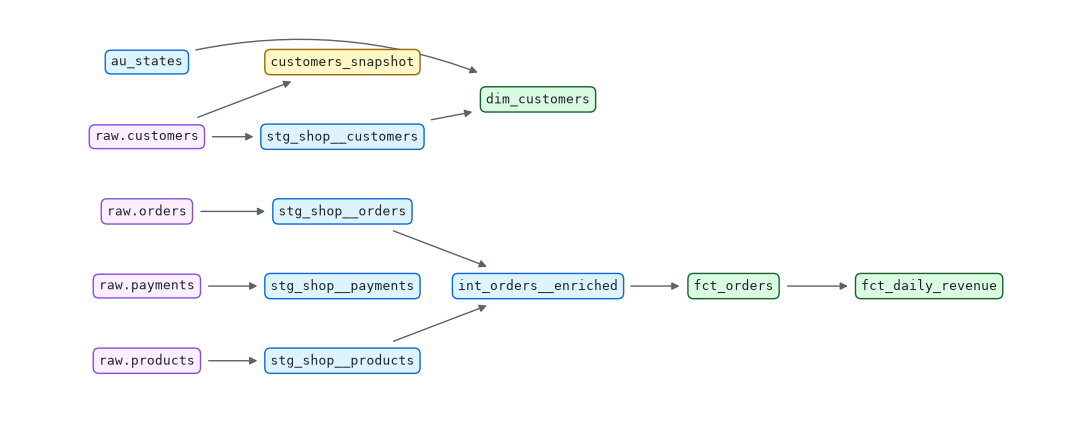

In [3]:
artifacts.lineage_figure()

## The catalogue

Each defect is declared as data: a function that damages the landing zone the
way a real incident would, a function that checks afterwards whether the marts
are actually wrong, and the outcome expected of it.

Declaring the expectation up front matters. It means the results table at the
end is not a transcript of what happened; it is a *comparison* against what
was predicted, and a closing assertion holds all fifteen to it.

In [4]:
from collections.abc import Callable
from dataclasses import dataclass

BUMP = "2026-07-30T09:00:00"  # loader clock for re-landed rows: past the watermark


@dataclass(frozen=True)
class Probe:
    name: str
    category: str
    change: str                   # what upstream did, in one sentence
    inject: Callable[[], None]
    damaged: Callable[[], bool]   # are the marts wrong afterwards?
    expect_outcome: str           # loud | silent
    expect_caught_by: str
    expect_damage: bool
    note: str


def fct_count() -> int:
    return shop.scalar("SELECT COUNT(*) FROM marts.fct_orders")


def order(order_id: int, **overrides) -> None:
    """A plausible new order, with the defect injected via overrides."""
    fields = {"order_id": order_id, "customer_id": 2, "product_id": 1, "quantity": 1,
              "unit_price_cents": 18900, "placed_at": BUMP}
    fields.update(overrides)
    shop.place_order(**fields)

**Keys and values**: defects a column-level test could plausibly declare.

In [5]:
PROBES = [
    Probe("duplicate key", "keys", "the loader lands order #33 twice",
          lambda: (order(33), order(33)),
          lambda: shop.scalar("SELECT COUNT(*) FROM marts.fct_orders WHERE order_id = 33") > 1,
          "loud", "generic: unique", False,
          "caught in staging; the marts never built"),
    Probe("null key", "keys", "an order arrives with no customer_id",
          lambda: order(33, customer_id=None),
          lambda: shop.scalar(
              "SELECT COUNT(*) FROM marts.fct_orders WHERE customer_id IS NULL") > 0,
          "loud", "generic: not_null", False,
          "caught in staging"),
    Probe("orphaned key", "keys", "an order references customer #99, who does not exist",
          lambda: order(33, customer_id=99),
          lambda: shop.scalar("SELECT COUNT(*) FROM marts.fct_orders WHERE customer_id = 99") > 0,
          "loud", "generic: relationships", True,
          "the alarm rang AND the orphan reached the mart (see below)"),

    Probe("invented status", "values", "upstream ships a new status: 'refunded'",
          lambda: order(33, status="refunded"),
          lambda: shop.scalar(
              "SELECT COUNT(*) FROM marts.fct_orders WHERE status = 'refunded'") > 0,
          "loud", "generic: accepted_values", False,
          "the enum grew; someone must decide what refunded means downstream"),
    Probe("negative quantity", "values", "an order for −3 drills lands",
          lambda: order(33, quantity=-3),
          lambda: shop.scalar("SELECT COUNT(*) FROM marts.fct_orders WHERE quantity < 0") > 0,
          "silent", "—", True,
          "no test bounds the sign; negative revenue reaches the mart"),
    Probe("unit error", "values", "one row lands with dollars in the cents column",
          lambda: shop.run_sql("UPDATE raw.orders SET unit_price_cents = 189, "
                               f"_loaded_at = '{BUMP}' WHERE order_id = 30"),
          lambda: shop.scalar(
              "SELECT unit_price FROM marts.fct_orders WHERE order_id = 30") < 10,
          "silent", "—", True,
          "type-clean, range-plausible, 100× wrong: the classic"),
    Probe("colliding SKU", "values", "a new product reuses an existing SKU",
          lambda: shop.run_sql("INSERT INTO raw.products VALUES "
                               f"(7, N'SKU-1001', N'Drill Bit Set', N'tools', 4900, '{BUMP}')"),
          lambda: fct_count() != 30 or shop.scalar(
              "SELECT COUNT(DISTINCT sku) FROM marts.fct_orders") != 6,
          "loud", "generic: unique", False,
          "secondary-key tests earn their keep; the mart was spared"),
]


**Business rules**: defects that break a rule no column-level test expresses.

In [6]:
PROBES += [
    Probe("fan-out join", "rules", "product #1 lands twice; the join would double every order",
          lambda: shop.run_sql("INSERT INTO raw.products VALUES "
                               f"(1, N'SKU-9999', N'Cordless Drill 18V', N'tools', 18900, '{BUMP}')"),
          lambda: fct_count() > 31,
          "loud", "generic: unique", False,
          "build order is the defence: the test fails, downstream is skipped"),
    Probe("shipped unpaid", "rules", "order #16 ships with no payment on file",
          lambda: shop.update_order_status(16, "shipped", updated_at=BUMP),
          lambda: shop.scalar("""
              SELECT COUNT(*) FROM marts.fct_orders o
              LEFT JOIN (SELECT order_id, SUM(amount) AS paid
                         FROM staging.stg_shop__payments GROUP BY order_id) p
                ON o.order_id = p.order_id
              WHERE o.status IN ('shipped', 'delivered')
                AND COALESCE(p.paid, 0) < o.line_total
          """) > 0,
          "loud", "singular test", True,
          "a rule no generic test expresses, but the mart merged it first"),
]


**Source-level failures**: properties of the feed, not of any row.

In [7]:
PROBES += [
    Probe("empty catalogue", "source", "the products feed lands zero rows; orders keep coming",
          lambda: (shop.run_sql("DELETE FROM raw.products"), order(33)),
          lambda: shop.scalar("SELECT COUNT(*) FROM marts.fct_orders WHERE sku IS NULL") > 0,
          "silent", "—", True,
          "every products test passes vacuously on an empty table"),
    Probe("vanished order", "source", "upstream hard-deletes order #6; the loader says nothing",
          lambda: shop.run_sql("DELETE FROM raw.orders WHERE order_id = 6"),
          lambda: shop.scalar("SELECT COUNT(*) FROM staging.stg_shop__orders") < fct_count(),
          "loud", "generic: relationships", True,
          "no test notices a missing row; the payment left behind raised the alarm"),
    Probe("stale feed", "source", "nothing has landed for days",
          None,  # nothing to inject: the frozen seed is already stale
          lambda: fct_count() != 30,
          "loud", "source freshness", False,
          "the only guard that watches the clock instead of the rows"),
]


**Schema and clock**: changes that are correct upstream and wrong downstream.

In [8]:
PROBES += [
    Probe("type widened", "schema", "quantity becomes bigint upstream; a 3-billion row lands",
          lambda: (shop.run_sql("ALTER TABLE raw.orders ALTER COLUMN quantity bigint"),
                   order(33, quantity=3_000_000_000)),
          lambda: shop.scalar(
              "SELECT quantity FROM marts.fct_orders WHERE order_id = 33") != 3_000_000_000,
          "silent", "—", False,
          "the column widened live and the 3-billion value landed intact"),

    Probe("clock skew", "time", "the loader switches to local time; new rows stamp behind the watermark",
          lambda: order(34, placed_at="2026-07-29T23:00:00", loaded_at="2026-07-29T01:00:00"),
          lambda: shop.scalar("SELECT COUNT(*) FROM staging.stg_shop__orders") != fct_count(),
          "silent", "—", True,
          "rows exist in staging and never reach the mart: part 2's lesson as a defect"),
    Probe("benign re-land", "time", "order #7 re-lands, byte-identical, with a fresh load stamp",
          lambda: shop.run_sql(f"UPDATE raw.orders SET _loaded_at = '{BUMP}' WHERE order_id = 7"),
          lambda: fct_count() != 30 or shop.scalar(
              "SELECT COUNT(*) FROM marts.fct_orders WHERE order_id = 7") != 1,
          "silent", "—", False,
          "merge absorbs the duplicate delivery; silence is sometimes correct"),
]
len(PROBES)


15

## The harness

Every probe runs the same loop:
1. reseed the landing zone
2. rebuild and verify green
3. inject the defect
4. `dbt build`
5. record what happened

Staleness is reported by a different dbt command, so that one probe swaps
`dbt build` for `dbt source freshness`.

The snapshot sits out entirely. Reseeding between probes would look to it
like mass rewrites of history, and part 3 already gave it a notebook.

`quiet=True` suppresses dbt's progress output but not its failure lines, so
the `FAIL` blocks below are the loud probes announcing themselves. The tidy
summary follows them.

In [9]:
def classify(results: dict) -> str:
    """Which guard spoke first? Test names carry their generic type."""
    for uid, r in results.items():
        if r["status"] in ("fail", "error"):
            if uid.startswith("model."):
                return "database error"
            name = uid.split(".")[2]
            for generic in ("unique", "not_null", "relationships", "accepted_values"):
                if name.startswith(generic):
                    return f"generic: {generic}"
            return "singular test"
    return "—"


def run_probe(p: Probe) -> dict:
    shop.reseed_raw()
    baseline = dbt("build", "--full-refresh", "--exclude", "customers_snapshot", quiet=True)
    assert baseline.success, f"baseline broken before probe {p.name!r}"
    assert fct_count() == 30

    if p.inject is None:
        build = dbt("source", "freshness", quiet=True)
        caught = "source freshness" if not build.success else "—"
    else:
        p.inject()
        build = dbt("build", "--exclude", "customers_snapshot", quiet=True)
        caught = classify(artifacts.run_results())

    return {
        "probe": p.name,
        "category": p.category,
        "upstream change": p.change,
        "outcome": "loud" if not build.success else "silent",
        "caught by": caught,
        "data damage": "yes" if p.damaged() else "—",
        "note": p.note,
    }


results = [run_probe(p) for p in PROBES]
for r in results:
    print(f"{r['outcome']:<6} · {r['caught by']:<22} · {r['probe']}")

12:34:39  19 of 39 FAIL 1 unique_stg_shop__orders_order_id ............................... [FAIL 1 in 0.10s]


12:34:40  [ERROR]: in test unique_stg_shop__orders_order_id (models/staging/shop/_stg_shop__models.yml)


12:34:40    Got 1 result, configured to fail if != 0


12:34:43  10 of 39 FAIL 1 not_null_stg_shop__orders_customer_id .......................... [FAIL 1 in 0.07s]


12:34:44  [ERROR]: in test not_null_stg_shop__orders_customer_id (models/staging/shop/_stg_shop__models.yml)


...

12:35:32    Got 1 result, configured to fail if != 0


12:35:37  1 of 1 ERROR STALE freshness of shop.orders .................................... [ERROR STALE in 0.02s]


12:35:37  [ERROR]: in source orders (models/staging/shop/_shop__sources.yml)


12:35:37    Status: error


loud   · generic: unique        · duplicate key
loud   · generic: not_null      · null key
loud   · generic: relationships · orphaned key
loud   · generic: accepted_values · invented status
silent · —                      · negative quantity
silent · —                      · unit error
loud   · generic: unique        · colliding SKU
loud   · generic: unique        · fan-out join
loud   · singular test          · shipped unpaid
silent · —                      · empty catalogue
loud   · generic: relationships · vanished order
loud   · source freshness       · stale feed
silent · —                      · type widened
silent · —                      · clock skew
silent · —                      · benign re-land


## The matrix

**Outcome** and **data damage** are independent axes. Read them separately.
Red marks the dangerous quadrant: silent *and* damaging, a wrong mart nothing
announced. Loud rows stay yellow even when the mart was damaged too; the
`data damage` column says which three, and the section after the matrix
explains how that happens.

In [10]:
matrix = pd.DataFrame(results)[
    ["category", "probe", "upstream change", "outcome", "caught by", "data damage", "note"]]
verdict.style(matrix)

category,probe,upstream change,outcome,caught by,data damage,note
keys,duplicate key,the loader lands order #33 twice,loud,generic: unique,—,caught in staging; the marts never built
keys,null key,an order arrives with no customer_id,loud,generic: not_null,—,caught in staging
keys,orphaned key,"an order references customer #99, who does not exist",loud,generic: relationships,yes,the alarm rang AND the orphan reached the mart (see below)
values,invented status,upstream ships a new status: 'refunded',loud,generic: accepted_values,—,the enum grew; someone must decide what refunded means downstream
values,negative quantity,an order for −3 drills lands,silent,—,yes,no test bounds the sign; negative revenue reaches the mart
values,unit error,one row lands with dollars in the cents column,silent,—,yes,"type-clean, range-plausible, 100× wrong: the classic"
values,colliding SKU,a new product reuses an existing SKU,loud,generic: unique,—,secondary-key tests earn their keep; the mart was spared
rules,fan-out join,product #1 lands twice; the join would double every order,loud,generic: unique,—,"build order is the defence: the test fails, downstream is skipped"
rules,shipped unpaid,order #16 ships with no payment on file,loud,singular test,yes,"a rule no generic test expresses, but the mart merged it first"
source,empty catalogue,the products feed lands zero rows; orders keep coming,silent,—,yes,every products test passes vacuously on an empty table


In [11]:
mismatches = [
    (p.name, field, want, got[field])
    for p, got in zip(PROBES, results)
    for field, want in [("outcome", p.expect_outcome),
                        ("caught by", p.expect_caught_by),
                        ("data damage", "yes" if p.expect_damage else "—")]
    if got[field] != want
]
assert not mismatches, f"probes that changed behaviour: {mismatches}"

tally = matrix.groupby(["outcome", "data damage"]).size()
assert tally.get(("loud", "—"), 0) == 6
assert tally.get(("loud", "yes"), 0) == 3
assert tally.get(("silent", "yes"), 0) == 4
assert tally.get(("silent", "—"), 0) == 2
assert (matrix["data damage"] == "yes").sum() == 7
print("✓ 15/15 matched expectations: 6 loud and clean · 3 loud but already damaged · "
      "4 silent and damaging · 2 silent and harmless")

✓ 15/15 matched expectations: 6 loud and clean · 3 loud but already damaged · 4 silent and damaging · 2 silent and harmless


**Seven of fifteen ended with wrong data in the marts.**

Four of those were completely silent. Those four are the ones the whole series
has been circling: a negative quantity, a price with dollars in the cents
column, a product feed that landed empty, and a loader clock running
backwards. Every one is a plausible value in a valid schema, so nothing
declared covered it, and an empty table passes every test ever written about
it, vacuously.

The other three are stranger. They failed the build *and* the mart was already
wrong.

---

## Why a red build doesn't always save you

`dbt build` runs a model's tests before its children. That is the documented
behaviour, and it is why the fan-out and duplicate-key probes above left the
marts clean.

So how did the orphaned key reach `fct_orders` while its test was failing?

The rule is narrower than the sentence suggests. Building the graph, dbt adds
an edge from a test to a downstream model only *"if the set of nodes the test
depends on is a subset of the upstream nodes for the given node"*
(`add_test_edges`, in dbt-core's `compilation.py`):

![when a failing test gates the build](img/test-gates.svg)

A `relationships` test touches two models: `stg_shop__orders` and
`stg_shop__customers`. `int_orders__enriched` descends from orders but not
from customers, so the subset check fails, no edge is added, and the test does
not gate it. It fails beside the pipeline rather than in front of it.

Note what the rule does *not* say. A two-parent test is not inherently
ungating: it would gate `dim_customers` perfectly well, because that model
descends from customers. Gating is a property of the *pair* (this test, that
model), not of the test alone.

That is a claim worth measuring rather than quoting. Same column, same model,
two tests differing only in how many models they touch:

In [12]:
def gate_test(bad_customer_id, label):
    """Break stg_shop__orders.customer_id one way; report what dbt skipped."""
    shop.reseed_raw()
    assert dbt("build", "--full-refresh", "--exclude", "customers_snapshot", quiet=True).success
    order(33, customer_id=bad_customer_id)
    dbt("build", "--exclude", "customers_snapshot", quiet=True)

    outcomes = artifacts.run_results()
    failed = next(uid.split(".")[2] for uid, r in outcomes.items() if r["status"] == "fail")
    return {
        "injected": label,
        "failing test": failed.split("_stg_shop")[0],
        "nodes skipped": sum(1 for r in outcomes.values() if r["status"] == "skipped"),
        "bad row in mart": bool(shop.scalar(
            "SELECT COUNT(*) FROM marts.fct_orders WHERE order_id = 33")),
    }


gate = pd.DataFrame([
    gate_test(None, "NULL customer_id (test touches 1 model)"),
    gate_test(99, "unknown customer #99 (test touches 2 models)"),
])
gate

12:36:03  10 of 39 FAIL 1 not_null_stg_shop__orders_customer_id .......................... [FAIL 1 in 0.04s]


12:36:03  [ERROR]: in test not_null_stg_shop__orders_customer_id (models/staging/shop/_stg_shop__models.yml)


12:36:03    Got 1 result, configured to fail if != 0


12:36:09  23 of 39 FAIL 1 relationships_stg_shop__orders_customer_id__customer_id__ref_stg_shop__customers_  [FAIL 1 in 0.08s]


12:36:10  [ERROR]: in test relationships_stg_shop__orders_customer_id__customer_id__ref_stg_shop__customers_ (models/staging/shop/_stg_shop__models.yml)


12:36:10    Got 1 result, configured to fail if != 0


,injected,failing test,nodes skipped,bad row in mart
0,NULL customer_id (test touches 1 model),not_null,11,False
1,unknown customer #99 (test touches 2 models),relationships,0,True


In [13]:
one_parent, two_parent = gate.iloc[0], gate.iloc[1]
# 11 is baked into img/test-gates.svg: if the project's shape changes and the
# skip count moves, fail here so the diagram is redrawn, not silently wrong.
assert one_parent["nodes skipped"] == 11 and not one_parent["bad row in mart"]
assert two_parent["nodes skipped"] == 0 and two_parent["bad row in mart"]
print(f"✓ one-parent test: {one_parent['nodes skipped']} nodes skipped, mart stayed clean")
print(f"✓ two-parent test: {two_parent['nodes skipped']} nodes skipped, bad row reached the mart")

✓ one-parent test: 11 nodes skipped, mart stayed clean
✓ two-parent test: 0 nodes skipped, bad row reached the mart


In [14]:
# The claim is that all three loud-but-damaged probes were caught by tests with
# two models upstream. Read it out of the manifest rather than asserting it.
tests = {uid.split(".")[2]: [n for n in node["depends_on"]["nodes"] if n.startswith("model.")]
         for uid, node in artifacts.manifest()["nodes"].items()
         if node["resource_type"] == "test"}

culprits = {name: len(models) for name, models in tests.items()
            if name.startswith(("relationships_stg_shop__orders_customer_id",
                                "relationships_stg_shop__payments_order_id",
                                "assert_payments_cover_shipped_orders"))}
gates = {name: len(models) for name, models in tests.items()
         if name.startswith(("not_null_stg_shop__orders", "unique_stg_shop__orders"))}

assert set(culprits.values()) == {2}, culprits
assert set(gates.values()) == {1}, gates
print("tests behind the three loud-but-damaged probes:")
for name, n in culprits.items():
    print(f"  {n} models upstream · {name[:62]}")
print()
print(f"✓ all three touch two models · {len(gates)} comparable tests touch one")

tests behind the three loud-but-damaged probes:
  2 models upstream · assert_payments_cover_shipped_orders
  2 models upstream · relationships_stg_shop__orders_customer_id__customer_id__ref_s
  2 models upstream · relationships_stg_shop__payments_order_id__order_id__ref_stg_s

✓ all three touch two models · 4 comparable tests touch one


All three loud-and-damaged probes were caught by tests that touch two models:
this one, the vanished order (whose alarm came from a `relationships` test on
*payments*, one lineage sideways), and the shipped-unpaid order, whose
singular test reads `fct_orders` itself, so the bad row had to be merged into
the mart before the test could possibly see it.

**The practical rule:** a test only gates the models that descend from
*everything* it touches. A single-parent test therefore gates its whole
subtree, which is why `not_null` and `unique` are reliable stoppers. A
cross-model test gates only where the lineages have already met, which, for a
`relationships` test between two staging models, is usually nowhere useful.

---

## Two rows worth staring at

**The unit error.** One row, dollars in a cents column. Type-correct, not
null, positive, a real order id, a real customer. Every declared expectation
holds while that day's revenue is wrong by two orders of magnitude. Tests
verify what you *declared*, and nobody declares "prices are usually about this
big."

**The empty catalogue.** Every test on `stg_shop__products` passed. `unique`
over zero rows is vacuously true, and that is not a dbt quirk; it is what the
SQL means. Emptiness is a *volume* property, and a build that loads nothing and tests
nothing-shaped data goes green all the way down. Volume is not something any
of the guards in the closing table measures.

One asymmetry worth naming, because the headline number rests on it in part.
`stg_shop__orders.customer_id` carries both `not_null` and a `relationships`
test; `stg_shop__orders.product_id` carries neither. That is why the empty
catalogue slips through as quietly as it does: nothing was ever declared
about an order's product. It is a realistic omission rather than a rigged one,
but a different set of declarations would move the score.

And one absence: **the contract never fired.** The catalogue did contain a
shape change (`quantity` widening to bigint), but it landed on `fct_orders`,
which carries no contract, and the adapter widened the column and moved on.
Contracts guard the columns you declared, on the models you declared them on,
against *developers* rather than against data.

---

## What the audit teaches

| guard | blind to |
|---|---|
| generic tests | anything undeclared: signs, ranges, volume |
| singular tests | every rule nobody wrote |
| contracts | values entirely |
| unit tests | production data entirely |
| source freshness | the content of what loaded |

Seven wrong marts out of fifteen is not an indictment of dbt. It is the honest
shape of declarative testing: **each guard catches exactly what someone
thought to declare, precisely when something runs it.**

Two things follow, and they are the practical takeaway from the whole series.

First, the four silent defects share a texture: plausible values, valid
shapes, quiet absences. Nothing declared covers them, so the affordable answer
is more singular tests, written from incident reviews rather than imagined in
advance.

Second, a failing test is an alarm, not automatically a gate. If a check must
*stop* bad data rather than merely report it, put it on a single model
upstream of everything it protects. If you only need it to warn, say so
explicitly with `severity: warn`, rather than discovering by accident which
of your tests were only ever warnings.